<a href="https://colab.research.google.com/github/lisakop/greeting-cli-v-000/blob/master/LisaKoperski_10_23_26_ForSubmittingAsDemo1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Mathematical Relationship: Free Ligand vs. Receptor Occupancy

For reversible, single-site ligand-receptor binding with no cooperative binding or competing ligands, the equilibrium fractional occupancy ($\theta$) is defined by the Langmuir equation:

$$\theta = \frac{L}{K_d + L}$$

Where:
* **$L$** is the free ligand concentration.
* **$K_d$** is the equilibrium dissociation constant (the concentration of ligand at which 50% of the receptors are occupied).
* **$\theta$** is the fractional occupancy (ranging from 0 to 1, or 0% to 100%).

#### Key Characteristics of the Curve:
1. **Hyperbolic Shape:** The relationship between $L$ and $\theta$ is a rectangular hyperbola.
2. **When $L \ll K_d$:** The equation simplifies to $\theta \approx \frac{L}{K_d}$. Occupancy increases almost linearly with free ligand concentration.
3. **When $L = K_d$:** The fractional occupancy is exactly half-maximal ($\theta = 0.5$ or 50%).
4. **When $L \gg K_d$:** The denominator is dominated by $L$, meaning $\theta \approx \frac{L}{L} = 1$. The receptors approach 100% saturation asymptotically.

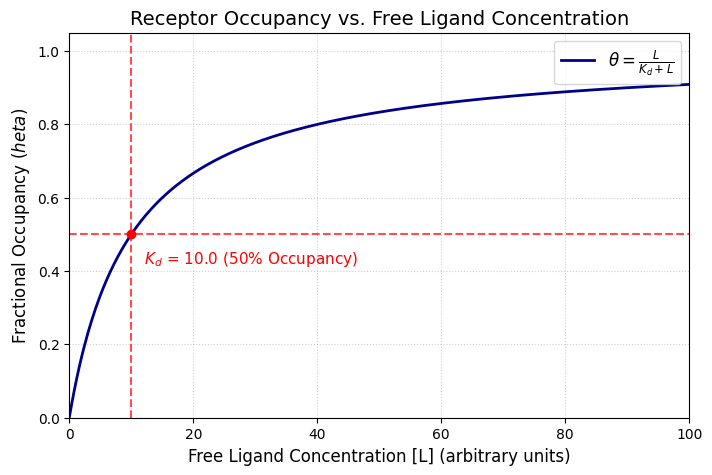

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the fractional occupancy function
def fractional_occupancy(L, Kd):
    return L / (Kd + L)

# Let's assume a Kd value (e.g., 10 nM)
Kd = 10.0

# Generate free ligand concentrations from 0 to 10 times the Kd value
L = np.linspace(0, 10 * Kd, 500)

# Calculate occupancy
theta = fractional_occupancy(L, Kd)

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(L, theta, label=r'$\theta = \frac{L}{K_d + L}$', color='darkblue', lw=2)

# Highlight Kd
plt.axvline(x=Kd, color='red', linestyle='--', alpha=0.7)
plt.axhline(y=0.5, color='red', linestyle='--', alpha=0.7)
plt.plot(Kd, 0.5, 'ro')  # Intersection point

# Labels and formatting
plt.title('Receptor Occupancy vs. Free Ligand Concentration', fontsize=14)
plt.xlabel('Free Ligand Concentration [L] (arbitrary units)', fontsize=12)
plt.ylabel(r'Fractional Occupancy ($	heta$)', fontsize=12)
plt.text(Kd + 2, 0.42, f'$K_d$ = {Kd} (50% Occupancy)', color='red', fontsize=11)
plt.xlim(0, max(L))
plt.ylim(0, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=12)
plt.show()

### Physiological Context & Chemical Equation

In cellular physiology, cholesterol is transported in the bloodstream primarily via Low-Density Lipoproteins (LDL). Cells take up cholesterol through receptor-mediated endocytosis, where LDL particles (acting as the ligand containing cholesterol) bind reversibly to LDL receptors (LDLR) on the cell membrane.

#### The Chemical Binding Equation:

$$L + R \underset{k_{off}}{\overset{k_{on}}{\rightleftharpoons}} LR$$

Where:
* **$L$**: Free ligand concentration (e.g., LDL containing cholesterol) $[M]$
* **$R$**: Unbound/free receptor concentration on the cell surface $[M]$
* **$LR$**: Ligand-receptor complex concentration $[M]$
* **$k_{on}$**: Association rate constant $[M^{-1}s^{-1}]$
* **$k_{off}$**: Dissociation rate constant $[s^{-1}]$
* **$K_d$**: Equilibrium dissociation constant ($K_d = k_{off}/k_{on}$) $[M]$

---

### System of Ordinary Differential Equations (ODEs)

Applying the Law of Mass Action, the dynamic changes in the concentrations of free ligand, free receptor, and the ligand-receptor complex over time ($t$) are described by the following system of non-linear differential equations:

1. **Rate of change of free ligand concentration ($L$):**
   $$\frac{dL}{dt} = -k_{on}[L][R] + k_{off}[LR]$$

2. **Rate of change of free receptor concentration ($R$):**
   $$\frac{dR}{dt} = -k_{on}[L][R] + k_{off}[LR]$$

3. **Rate of change of ligand-receptor complex concentration ($LR$):**
   $$\frac{d[LR]}{dt} = k_{on}[L][R] - k_{off}[LR]$$

Assuming a closed system with conservation of total receptors ($R_{total} = R + LR$), we can substitute $R = R_{total} - LR$ to reduce the system.

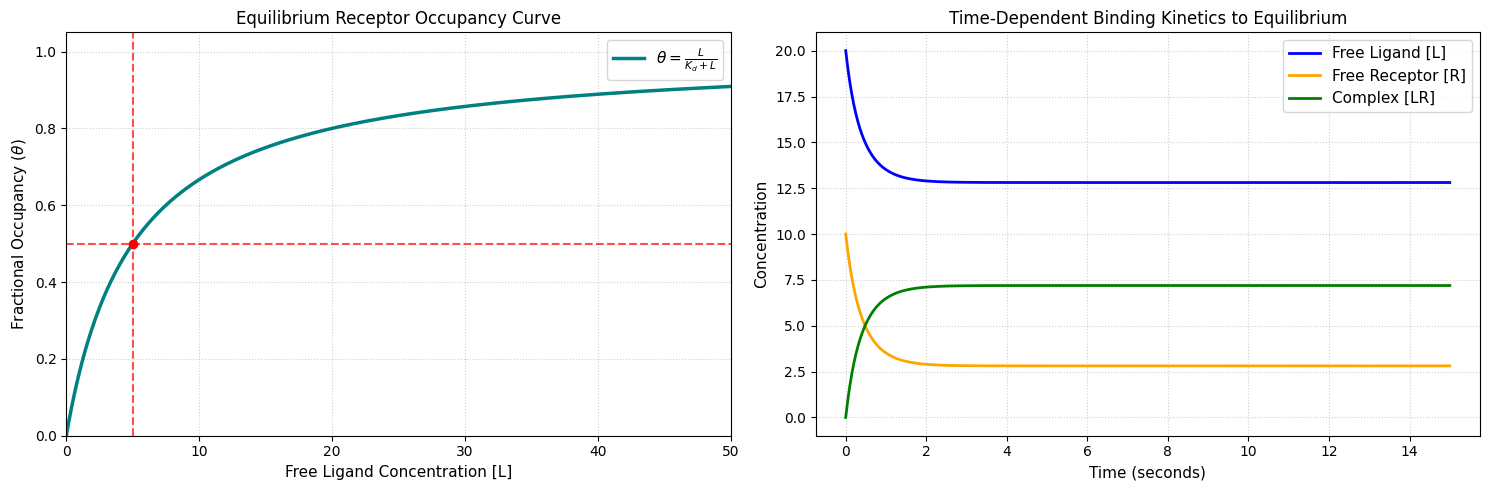

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Illustrative Parameters ---
Kd_val = 5.0      # Dissociation constant (arbitrary units)
kon_val = 0.1     # Association rate constant
koff_val = 0.5    # Dissociation rate constant (koff = kon * Kd)

# --- 1. Equilibrium Occupancy Data ---
L_eq = np.linspace(0, 50, 500)
theta_eq = L_eq / (Kd_val + L_eq)

# --- 2. Time-Dependent Simulation Data ---
# System of ODEs
def binding_system(t, y, kon, koff):
    L, R, LR = y
    dL_dt = -kon * L * R + koff * LR
    dR_dt = -kon * L * R + koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

y0 = [20.0, 10.0, 0.0]  # Initial state: [L_0, R_0, LR_0]
t_span = (0, 15)
t_eval = np.linspace(0, 15, 300)
sol = solve_ivp(binding_system, t_span, y0, args=(kon_val, koff_val), t_eval=t_eval)

# --- Plotting Side-by-Side ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left Plot: Equilibrium binding curve
axes[0].plot(L_eq, theta_eq, color='teal', lw=2.5, label=r'$\theta = \frac{L}{K_d + L}$')
axes[0].axvline(x=Kd_val, color='red', linestyle='--', alpha=0.7)
axes[0].axhline(y=0.5, color='red', linestyle='--', alpha=0.7)
axes[0].plot(Kd_val, 0.5, 'ro')
axes[0].set_title('Equilibrium Receptor Occupancy Curve', fontsize=12)
axes[0].set_xlabel('Free Ligand Concentration [L]', fontsize=11)
axes[0].set_ylabel(r'Fractional Occupancy ($\theta$)', fontsize=11)
axes[0].set_xlim(0, 50)
axes[0].set_ylim(0, 1.05)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(fontsize=11)

# Right Plot: Time-dependent kinetics
axes[1].plot(sol.t, sol.y[0], label='Free Ligand [L]', color='blue', lw=2)
axes[1].plot(sol.t, sol.y[1], label='Free Receptor [R]', color='orange', lw=2)
axes[1].plot(sol.t, sol.y[2], label='Complex [LR]', color='green', lw=2)
axes[1].set_title('Time-Dependent Binding Kinetics to Equilibrium', fontsize=12)
axes[1].set_xlabel('Time (seconds)', fontsize=11)
axes[1].set_ylabel('Concentration', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

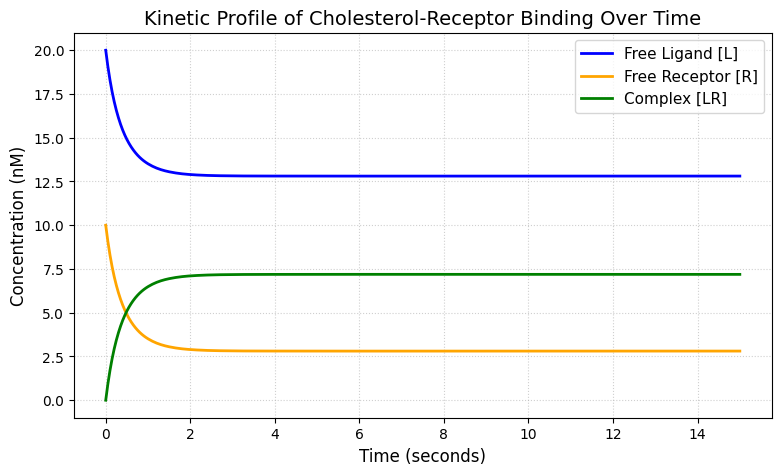

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# This is part of Section 1 for Demo 1 (Initial Physiological Model): Define the system of ODEs
def binding_system(t, y, kon, koff):
    L, R, LR = y
    # dL/dt = -kon * L * R + koff * LR
    dL_dt = -kon * L * R + koff * LR
    # dR/dt = -kon * L * R + koff * LR
    dR_dt = -kon * L * R + koff * LR
    # dLR/dt = kon * L * R - koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

# These are rate constants (i.e., Kinetic parameters)
kon = 0.1     # M^-1 s^-1 (assumed rate) = Association rate (e.g., 1/(nM *s))
koff = 0.5    # s^-1 = Dissacotion rate (e.g., 1/s)
Kd = koff / kon

# Initial conditions: [L_0, R_0, LR_0]
# e.g., starting with 20 nM free ligand (i.e., free cholesterol), 10 nM free receptors (i.e., free receptor), and no complexes
y0 = [20.0, 10.0, 0.0]
t_span = (0, 15)  # Simulate for 15 seconds
t_eval = np.linspace(0, 15, 300)

# Solve the ODEs
sol = solve_ivp(binding_system, t_span, y0, args=(kon, koff), t_eval=t_eval)

# Plot the trajectory to equilibrium
plt.figure(figsize=(9, 5))
plt.plot(sol.t, sol.y[0], label='Free Ligand [L]', color='blue', lw=2)
plt.plot(sol.t, sol.y[1], label='Free Receptor [R]', color='orange', lw=2)
plt.plot(sol.t, sol.y[2], label='Complex [LR]', color='green', lw=2)

plt.title('Kinetic Profile of Cholesterol-Receptor Binding Over Time', fontsize=14)
plt.xlabel('Time (seconds)', fontsize=12)
plt.ylabel('Concentration (nM)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

In [ ]:
l

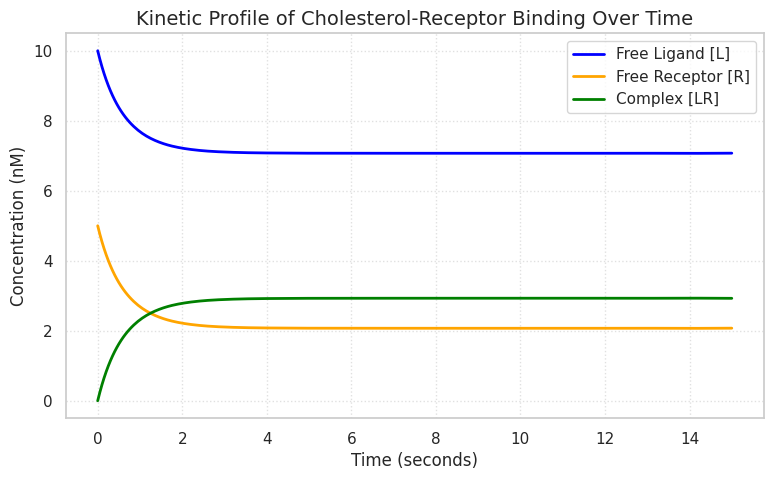

In [ ]:
# Lisa modifying some of the parameters above
#  (i.e., t_span from 15-->100 seconds, free cholesterol from 20 mM to 10 nM, and free receptors from 10nM to 5nM)
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# This is part of Section 2 for Demo 1 (Build and understand the implementation):
# Define the system of ODEs
def binding_system(t, y, kon, koff):
    L, R, LR = y
    # dL/dt = -kon * L * R + koff * LR
    dL_dt = -kon * L * R + koff * LR
    # dR/dt = -kon * L * R + koff * LR
    dR_dt = -kon * L * R + koff * LR
    # dLR/dt = kon * L * R - koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

# These are rate constants (i.e., Kinetic parameters)
kon = 0.1     # M^-1 s^-1 (assumed rate) = Association rate (e.g., 1/(nM *s))
koff = 0.5    # s^-1 = Disassociation rate (e.g., 1/s)
Kd = koff / kon

# Initial conditions WHICH ARE CHANGING IN THIS SECTION 2 FOR DEMO 1: [L_0, R_0, LR_0]
# e.g., starting with 10 nM free ligand (i.e., free cholesterol), 5 nM free receptors (i.e., free receptor), and no complexes
y0 = [10.0, 5.0, 0.0]
t_span = (0, 100)  # Simulate for 100 seconds
t_eval = np.linspace(0, 15, 300)

# Solve the ODEs
sol = solve_ivp(binding_system, t_span, y0, args=(kon, koff), t_eval=t_eval)

# Plot the trajectory to equilibrium
plt.figure(figsize=(9, 5))
plt.plot(sol.t, sol.y[0], label='Free Ligand [L]', color='blue', lw=2)
plt.plot(sol.t, sol.y[1], label='Free Receptor [R]', color='orange', lw=2)
plt.plot(sol.t, sol.y[2], label='Complex [LR]', color='green', lw=2)

plt.title('Kinetic Profile of Cholesterol-Receptor Binding Over Time', fontsize=14)
plt.xlabel('Time (seconds)', fontsize=12)
plt.ylabel('Concentration (nM)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

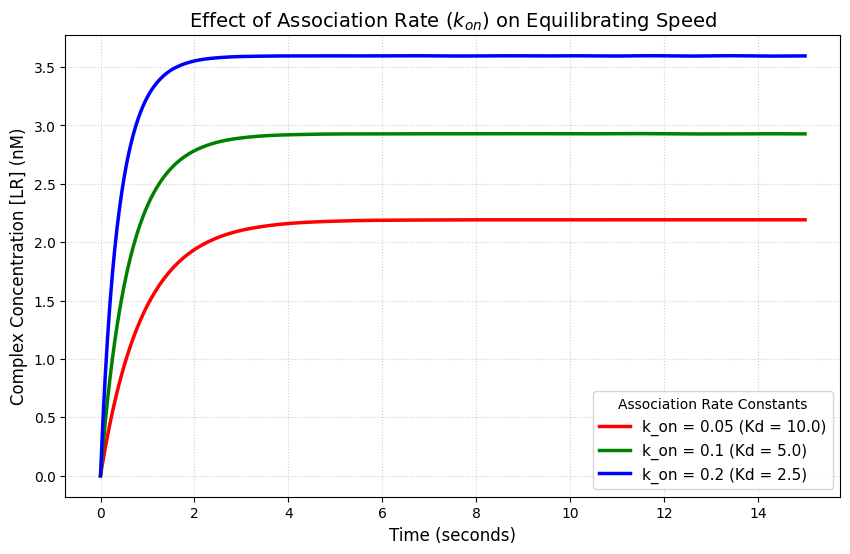

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Define the system of ODEs
def binding_system(t, y, kon, koff):
    L, R, LR = y
    dL_dt = -kon * L * R + koff * LR
    dR_dt = -kon * L * R + koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

# Fixed parameters
koff = 0.5            # Dissociation rate (1/s)
y0 = [10.0, 5.0, 0.0] # Initial concentrations: [Free Ligand, Free Receptor, Complex]
t_span = (0, 15)      # 15 seconds simulation
t_eval = np.linspace(0, 15, 300)

# Test different values of association rate kon
kon_values = [0.05, 0.1, 0.2]
colors = ['red', 'green', 'blue']

plt.figure(figsize=(10, 6))

for kon, color in zip(kon_values, colors):
    sol = solve_ivp(binding_system, t_span, y0, args=(kon, koff), t_eval=t_eval)
    # Plotting the formation of the ligand-receptor complex [LR]
    plt.plot(sol.t, sol.y[2], label=f'k_on = {kon} (Kd = {koff/kon:.1f})', color=color, lw=2.5)

plt.title('Effect of Association Rate ($k_{on}$) on Equilibrating Speed', fontsize=14)
plt.xlabel('Time (seconds)', fontsize=12)
plt.ylabel('Complex Concentration [LR] (nM)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Association Rate Constants', fontsize=11)
plt.show()

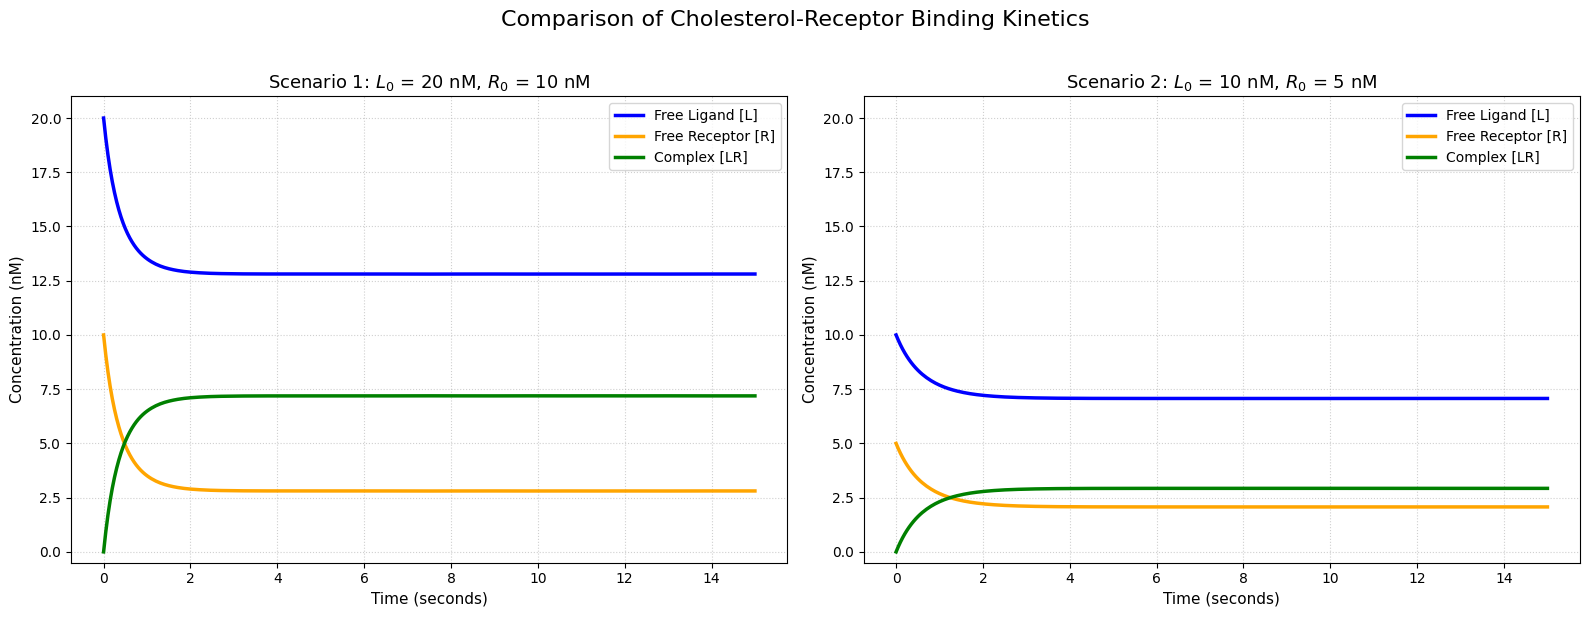

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Define the system of ODEs
def binding_system(t, y, kon, koff):
    L, R, LR = y
    dL_dt = -kon * L * R + koff * LR
    dR_dt = -kon * L * R + koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

# Kinetic parameters (same for both scenarios)
kon = 0.1     # M^-1 s^-1
koff = 0.5    # s^-1
t_span = (0, 15)
t_eval = np.linspace(0, 15, 300)

# Scenario 1 Initial Conditions: L_0 = 20.0 nM, R_0 = 10.0 nM
y0_scen1 = [20.0, 10.0, 0.0]
sol_scen1 = solve_ivp(binding_system, t_span, y0_scen1, args=(kon, koff), t_eval=t_eval)

# Scenario 2 Initial Conditions: L_0 = 10.0 nM, R_0 = 5.0 nM
y0_scen2 = [10.0, 5.0, 0.0]
sol_scen2 = solve_ivp(binding_system, t_span, y0_scen2, args=(kon, koff), t_eval=t_eval)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

# Left Plot: Scenario 1
axes[0].plot(sol_scen1.t, sol_scen1.y[0], label='Free Ligand [L]', color='blue', lw=2.5)
axes[0].plot(sol_scen1.t, sol_scen1.y[1], label='Free Receptor [R]', color='orange', lw=2.5)
axes[0].plot(sol_scen1.t, sol_scen1.y[2], label='Complex [LR]', color='green', lw=2.5)
axes[0].set_title('Scenario 1: $L_0$ = 20 nM, $R_0$ = 10 nM', fontsize=13)
axes[0].set_xlabel('Time (seconds)', fontsize=11)
axes[0].set_ylabel('Concentration (nM)', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(fontsize=10)
axes[0].set_ylim(-0.5, 21.0)

# Right Plot: Scenario 2
axes[1].plot(sol_scen2.t, sol_scen2.y[0], label='Free Ligand [L]', color='blue', lw=2.5)
axes[1].plot(sol_scen2.t, sol_scen2.y[1], label='Free Receptor [R]', color='orange', lw=2.5)
axes[1].plot(sol_scen2.t, sol_scen2.y[2], label='Complex [LR]', color='green', lw=2.5)
axes[1].set_title('Scenario 2: $L_0$ = 10 nM, $R_0$ = 5 nM', fontsize=13)
axes[1].set_xlabel('Time (seconds)', fontsize=11)
axes[1].set_ylabel('Concentration (nM)', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(fontsize=10)
axes[1].set_ylim(-0.5, 21.0)

plt.suptitle('Comparison of Cholesterol-Receptor Binding Kinetics', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Individual Scenario Trajectories and $k_{off}$ Sensitivity Analysis

Below, we separate the simulations for Scenario 1 and Scenario 2. For each scenario, we analyze the effect of varying the dissociation rate constant $k_{off}$ on the formation of the ligand-receptor complex ($LR$) over time, keeping $k_{on} = 0.1\text{ nM}^{-1}\text{s}^{-1}$ constant.

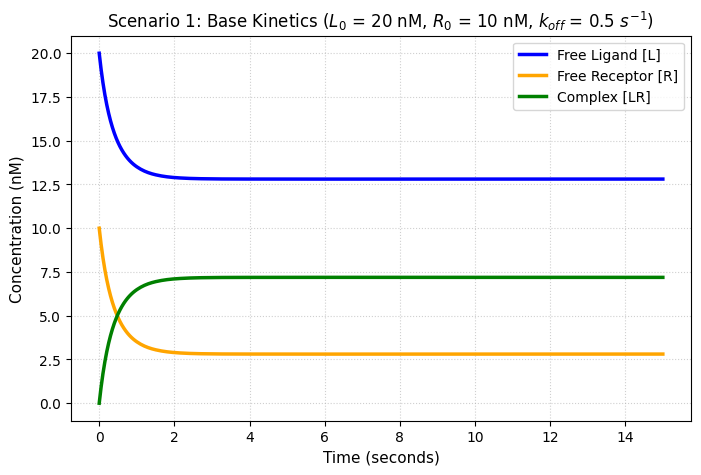

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def binding_system(t, y, kon, koff):
    L, R, LR = y
    dL_dt = -kon * L * R + koff * LR
    dR_dt = -kon * L * R + koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

t_span = (0, 15)
t_eval = np.linspace(0, 15, 300)
kon = 0.1

# --- SCENARIO 1: L0 = 20.0 nM, R0 = 10.0 nM ---
y0_scen1 = [20.0, 10.0, 0.0]

# Standard Simulation with koff = 0.5
sol_scen1 = solve_ivp(binding_system, t_span, y0_scen1, args=(kon, 0.5), t_eval=t_eval)

# Plot Scenario 1 base kinetics
plt.figure(figsize=(8, 5))
plt.plot(sol_scen1.t, sol_scen1.y[0], label='Free Ligand [L]', color='blue', lw=2.5)
plt.plot(sol_scen1.t, sol_scen1.y[1], label='Free Receptor [R]', color='orange', lw=2.5)
plt.plot(sol_scen1.t, sol_scen1.y[2], label='Complex [LR]', color='green', lw=2.5)
plt.title('Scenario 1: Base Kinetics ($L_0$ = 20 nM, $R_0$ = 10 nM, $k_{off}$ = 0.5 $s^{-1}$)', fontsize=12)
plt.xlabel('Time (seconds)', fontsize=11)
plt.ylabel('Concentration (nM)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.show()

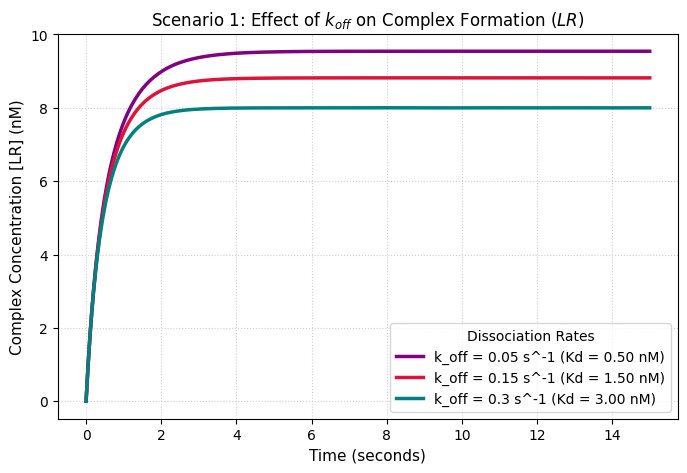

In [ ]:
# --- SCENARIO 1: Parameter Sweep for koff ---
koff_values = [0.05, 0.15, 0.30]
colors = ['purple', 'crimson', 'teal']

plt.figure(figsize=(8, 5))
for koff, color in zip(koff_values, colors):
    sol = solve_ivp(binding_system, t_span, y0_scen1, args=(kon, koff), t_eval=t_eval)
    Kd_val = koff / kon
    plt.plot(sol.t, sol.y[2], label=f'k_off = {koff} s^-1 (Kd = {Kd_val:.2f} nM)', color=color, lw=2.5)

plt.title('Scenario 1: Effect of $k_{off}$ on Complex Formation ($LR$)', fontsize=12)
plt.xlabel('Time (seconds)', fontsize=11)
plt.ylabel('Complex Concentration [LR] (nM)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Dissociation Rates', fontsize=10)
plt.show()

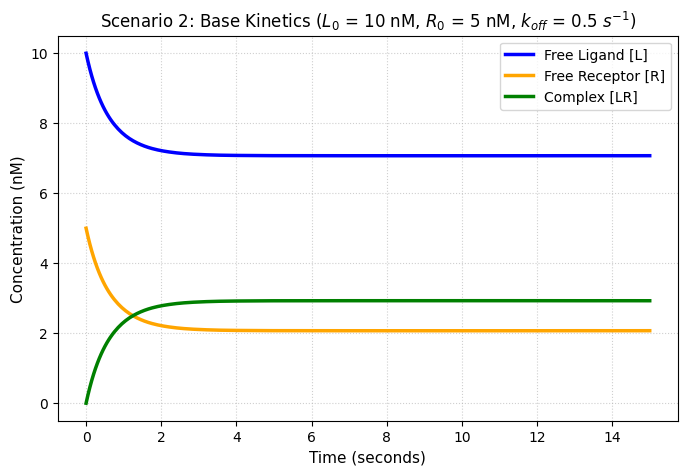

In [ ]:
# --- SCENARIO 2: L0 = 10.0 nM, R0 = 5.0 nM ---
y0_scen2 = [10.0, 5.0, 0.0]

# Standard Simulation with koff = 0.5
sol_scen2 = solve_ivp(binding_system, t_span, y0_scen2, args=(kon, 0.5), t_eval=t_eval)

# Plot Scenario 2 base kinetics
plt.figure(figsize=(8, 5))
plt.plot(sol_scen2.t, sol_scen2.y[0], label='Free Ligand [L]', color='blue', lw=2.5)
plt.plot(sol_scen2.t, sol_scen2.y[1], label='Free Receptor [R]', color='orange', lw=2.5)
plt.plot(sol_scen2.t, sol_scen2.y[2], label='Complex [LR]', color='green', lw=2.5)
plt.title('Scenario 2: Base Kinetics ($L_0$ = 10 nM, $R_0$ = 5 nM, $k_{off}$ = 0.5 $s^{-1}$)', fontsize=12)
plt.xlabel('Time (seconds)', fontsize=11)
plt.ylabel('Concentration (nM)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.show()

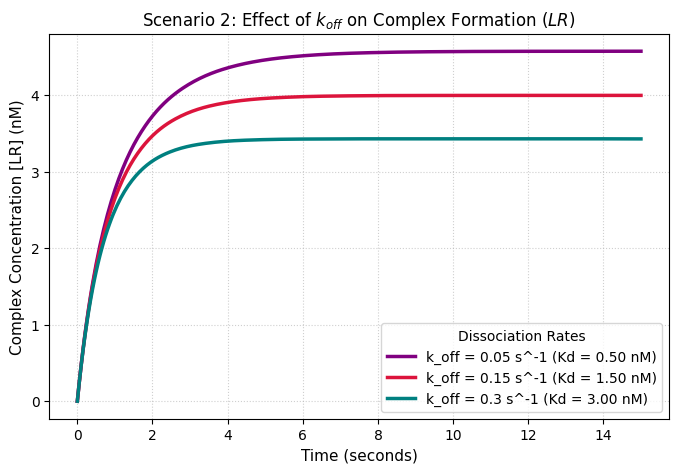

In [ ]:
# --- SCENARIO 2: Parameter Sweep for koff ---
plt.figure(figsize=(8, 5))
for koff, color in zip(koff_values, colors):
    sol = solve_ivp(binding_system, t_span, y0_scen2, args=(kon, koff), t_eval=t_eval)
    Kd_val = koff / kon
    plt.plot(sol.t, sol.y[2], label=f'k_off = {koff} s^-1 (Kd = {Kd_val:.2f} nM)', color=color, lw=2.5)

plt.title('Scenario 2: Effect of $k_{off}$ on Complex Formation ($LR$)', fontsize=12)
plt.xlabel('Time (seconds)', fontsize=11)
plt.ylabel('Complex Concentration [LR] (nM)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Dissociation Rates', fontsize=10)
plt.show()

### Dynamic Receptor Occupancy ($\theta$) vs. Free Ligand Concentration ($[L]$)

In this section, we plot the trajectory of receptor occupancy defined as:

$$\theta(t) = \frac{[LR](t)}{R_{total}}$$

against the free ligand concentration $[L](t)$ at each corresponding time point. This maps out how the system state dynamically moves toward equilibrium along its binding path under different $k_{off}$ values.

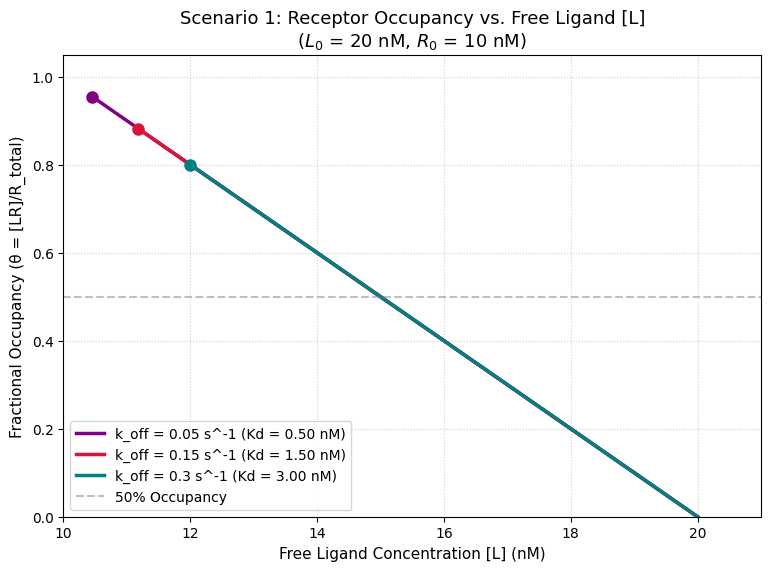

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def binding_system(t, y, kon, koff):
    L, R, LR = y
    dL_dt = -kon * L * R + koff * LR
    dR_dt = -kon * L * R + koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

t_span = (0, 30)  # Use slightly longer time to ensure full equilibrium
t_eval = np.linspace(0, 30, 500)
kon = 0.1
koff_values = [0.05, 0.15, 0.30]
colors = ['purple', 'crimson', 'teal']

# --- SCENARIO 1: L0 = 20.0 nM, R0 = 10.0 nM ---
y0_scen1 = [20.0, 10.0, 0.0]
R_total_scen1 = 10.0

plt.figure(figsize=(9, 6))
for koff, color in zip(koff_values, colors):
    sol = solve_ivp(binding_system, t_span, y0_scen1, args=(kon, koff), t_eval=t_eval)
    free_L = sol.y[0]
    LR_complex = sol.y[2]
    occupancy = LR_complex / R_total_scen1
    Kd_val = koff / kon

    # Plot dynamic trajectory path
    plt.plot(free_L, occupancy, label=f'k_off = {koff} s^-1 (Kd = {Kd_val:.2f} nM)', color=color, lw=2.5)
    # Mark the final equilibrium point
    plt.plot(free_L[-1], occupancy[-1], marker='o', color=color, markersize=8)

# Reference line for 50% occupancy
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='50% Occupancy')

plt.title('Scenario 1: Receptor Occupancy vs. Free Ligand [L]\n($L_0$ = 20 nM, $R_0$ = 10 nM)', fontsize=13)
plt.xlabel('Free Ligand Concentration [L] (nM)', fontsize=11)
plt.ylabel('Fractional Occupancy (θ = [LR]/R_total)', fontsize=11)
plt.xlim(10, 21)
plt.ylim(0, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left', fontsize=10)
plt.show()

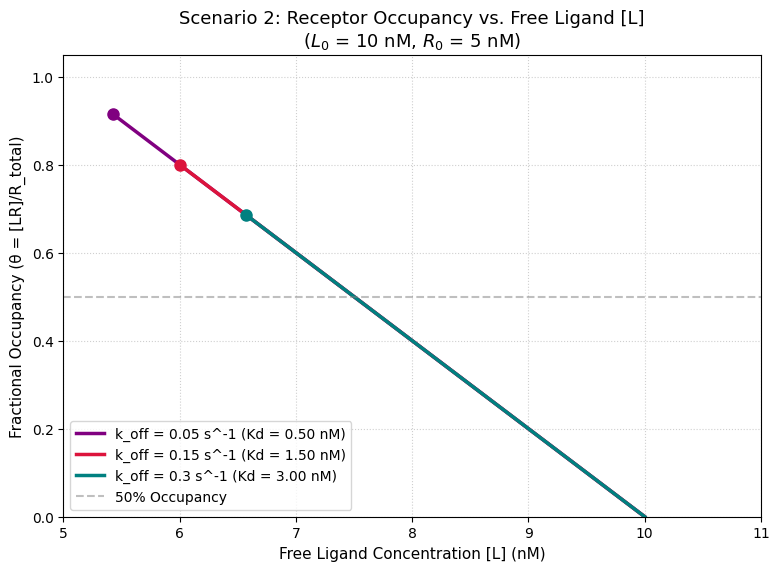

In [ ]:
# --- SCENARIO 2: L0 = 10.0 nM, R0 = 5.0 nM ---
y0_scen2 = [10.0, 5.0, 0.0]
R_total_scen2 = 5.0

plt.figure(figsize=(9, 6))
for koff, color in zip(koff_values, colors):
    sol = solve_ivp(binding_system, t_span, y0_scen2, args=(kon, koff), t_eval=t_eval)
    free_L = sol.y[0]
    LR_complex = sol.y[2]
    occupancy = LR_complex / R_total_scen2
    Kd_val = koff / kon

    # Plot dynamic trajectory path
    plt.plot(free_L, occupancy, label=f'k_off = {koff} s^-1 (Kd = {Kd_val:.2f} nM)', color=color, lw=2.5)
    # Mark the final equilibrium point
    plt.plot(free_L[-1], occupancy[-1], marker='o', color=color, markersize=8)

# Reference line for 50% occupancy
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='50% Occupancy')

plt.title('Scenario 2: Receptor Occupancy vs. Free Ligand [L]\n($L_0$ = 10 nM, $R_0$ = 5 nM)', fontsize=13)
plt.xlabel('Free Ligand Concentration [L] (nM)', fontsize=11)
plt.ylabel('Fractional Occupancy (θ = [LR]/R_total)', fontsize=11)
plt.xlim(5, 11)
plt.ylim(0, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left', fontsize=10)
plt.show()

### Comparison of Kinetics Scenarios: Model Specifications

| Feature | Scenario 1 | Scenario 2 |
| :--- | :--- | :--- |
| **Starting Conditions** | **$L_0 = 20.0\text{ nM}$, $R_0 = 10.0\text{ nM}$, $LR_0 = 0.0\text{ nM}$** | **$L_0 = 10.0\text{ nM}$, $R_0 = 5.0\text{ nM}$, $LR_0 = 0.0\text{ nM}$** |
| **Model Equations (ODEs)** | <ul><li>$\frac{dL}{dt} = -k_{on}[L][R] + k_{off}[LR]$</li><li>$\frac{dR}{dt} = -k_{on}[L][R] + k_{off}[LR]$</li><li>$\frac{d[LR]}{dt} = k_{on}[L][R] - k_{off}[LR]$</li></ul> | <ul><li>$\frac{dL}{dt} = -k_{on}[L][R] + k_{off}[LR]$</li><li>$\frac{dR}{dt} = -k_{on}[L][R] + k_{off}[LR]$</li><li>$\frac{d[LR]}{dt} = k_{on}[L][R] - k_{off}[LR]$</li></ul> |
| **Variables** | <ul><li>$L$: Free cholesterol/ligand concentration</li><li>$R$: Free cell-surface receptor concentration</li><li>$LR$: Ligand-receptor complex concentration</li></ul> | <ul><li>$L$: Free cholesterol/ligand concentration</li><li>$R$: Free cell-surface receptor concentration</li><li>$LR$: Ligand-receptor complex concentration</li></ul> |
| **Kinetic Parameters** | <ul><li>$k_{on} = 0.1\text{ nM}^{-1}\text{s}^{-1}$</li><li>$k_{off} = 0.5\text{ s}^{-1}$</li><li>$K_d = \frac{k_{off}}{k_{on}} = 5.0\text{ nM}$</li></ul> | <ul><li>$k_{on} = 0.1\text{ nM}^{-1}\text{s}^{-1}$</li><li>$k_{off} = 0.5\text{ s}^{-1}$</li><li>$K_d = \frac{k_{off}}{k_{on}} = 5.0\text{ nM}$</li></ul> |
| **Units** | <ul><li>Concentrations ($L$, $R$, $LR$): Nanomolar ($\text{nM}$)</li><li>Time ($t$): Seconds ($\text{s}$)</li><li>$k_{on}$: $\text{nM}^{-1}\text{s}^{-1}$</li><li>$k_{off}$: $\text{s}^{-1}$</li></ul> | <ul><li>Concentrations ($L$, $R$, $LR$): Nanomolar ($\text{nM}$)</li><li>Time ($t$): Seconds ($\text{s}$)</li><li>$k_{on}$: $\text{nM}^{-1}\text{s}^{-1}$</li><li>$k_{off}$: $\text{s}^{-1}$</li></ul> |
| **Key Assumptions** | <ul><li>**Closed System:** No synthesis, degradation, internal trafficking, or endocytosis of the ligand, receptors, or complexes takes place during the observed time window.</li><li>**Homogeneous Mixing:** Reactions take place in a well-mixed volume near the membrane surface.</li><li>**Simple 1:1 Stoichiometry:** One cholesterol ligand binds reversibly to one receptor without cooperative effects.</li></ul> | <ul><li>**Closed System:** No synthesis, degradation, internal trafficking, or endocytosis of the ligand, receptors, or complexes takes place during the observed time window.</li><li>**Homogeneous Mixing:** Reactions take place in a well-mixed volume near the membrane surface.</li><li>**Simple 1:1 Stoichiometry:** One cholesterol ligand binds reversibly to one receptor without cooperative effects.</li></ul> |

### Summary of Dimensional Units in the Equation

| Variable/Parameter | Symbol | Type | Typical Physiological Units |
| :--- | :--- | :--- | :--- |
| **Free Ligand Concentration** | $L$ | Variable | Nanomolar ($\text{nM}$) or Micromolar ($\mu\text{M}$) |
| **Free Receptor Concentration** | $R$ | Variable | Nanomolar ($\text{nM}$) or sites/cell |
| **Ligand-Receptor Complex** | $LR$ | Variable | Nanomolar ($\text{nM}$) or complexes/cell |
| **Association Rate Constant** | $k_{on}$ | Parameter | $\text{nM}^{-1}\text{s}^{-1}$ or $\text{M}^{-1}\text{s}^{-1}$ |
| **Dissociation Rate Constant** | $k_{off}$ | Parameter | Reciprocal seconds ($\text{s}^{-1}$) |
| **Equilibrium Dissociation Constant** | $K_d$ | Parameter | Nanomolar ($\text{nM}$) or Micromolar ($\mu\text{M}$) |
| **Time** | $t$ | Independent Variable | Seconds ($\text{s}$) or Minutes ($\text{min}$) |

---

### Conceptual Comparison of $k_{on}$ and $k_{off}$

* **$k_{on}$ (Association Rate Constant):**
  * **Concept:** Measures how fast the ligand and receptor find each other and collide productively to bind.
  * **Nature:** It is a second-order rate constant. Its speed depends directly on the concentrations of both the free ligand and free receptor.
  * **Intuition:** Higher $k_{on}$ values represent a highly efficient or rapid binding event upon physical collision.

* **$k_{off}$ (Dissociation Rate Constant):**
  * **Concept:** Measures the intrinsic stability of the ligand-receptor complex once formed, determining how easily they break apart.
  * **Nature:** It is a first-order rate constant. Its speed depends solely on the concentration of the complex ($[LR]$) and is independent of free ligand concentration.
  * **Intuition:** A lower $k_{off}$ indicates a highly stable complex ("tight binding" or high residence time), whereas a high $k_{off}$ means the complex is highly unstable and dissociates rapidly.

### Kinetics with Time-Varying Ligand Concentrations

Physiologically, cholesterol/LDL concentration is rarely static. It fluctuates over time due to dietary intake, clearance, and metabolic rates.

Here we model a system where the total ligand pool is subject to a constant physiological clearance (decay) rate while starting at three different baselines representing:
* **Normal Cholesterol:** $L_0 = 0.5\text{ nM}$
* **High Cholesterol:** $L_0 = 0.6\text{ nM}$
* **Very High Cholesterol:** $L_0 = 0.75\text{ nM}$

We define a time-dependent decay for the free ligand to simulate dynamic clearance:
$$\frac{dL}{dt} = -k_{on}[L][R] + k_{off}[LR] - k_{clearance}[L]$$

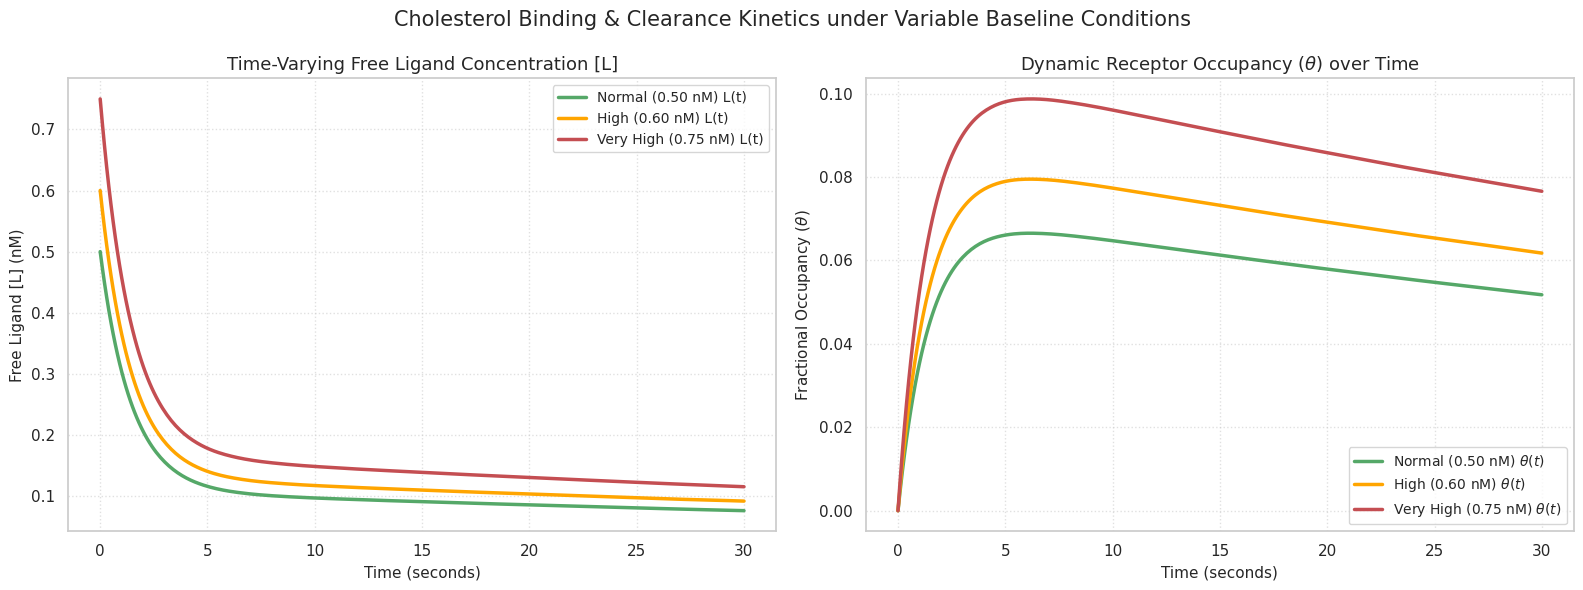

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Dynamic ODE system with active ligand clearance
# This is to satisfy Sections 2 and 3 (Predict and explore) of Demo 1:
# Lisa prediction: I predict that high-cholesterol will negatively impact free ligand concentration so as to increase receptor occupancy since the baseline will be higher.
#
# In my previous session with Colab, here is what Colab said: In biological systems, cellular responses often depend (cont)
# on the relative change in receptor occupancy (the signal-to-noise ratio) rather than the absolute level. (cont)
# Under chronically high cholesterol levels ($0.75\text{ nM}$$0.75\text{ nM}$), the background "noise" is high, keeping $60\%$$60\%$ of receptors constitutively active. (cont)
# Consequently, when a physiological pulse occurs, the relative response is significantly weaker. (cont)
# This mathematically demonstrates how chronic hypercholesterolemia leads to cellular desensitization and a blunted physiological response.
def dynamic_binding_system(t, y, kon, koff, k_clear):
    L, R, LR = y
    # Free ligand clearance rate acts as a sink
    dL_dt = -kon * L * R + koff * LR - k_clear * L
    dR_dt = -kon * L * R + koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

# Parameters
kon = 0.1       # nM^-1 s^-1
koff = 0.15     # s^-1
k_clear = 0.05  # s^-1 (clearance rate constant)

R0 = 5.0        # Constant starting receptor pool (nM)
t_span = (0, 30)
t_eval = np.linspace(0, 30, 300)

cholesterol_levels = {
    'Normal (0.50 nM)': 0.50,
    'High (0.60 nM)': 0.60,
    'Very High (0.75 nM)': 0.75
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ['g', 'orange', 'r']

for (label, L0), color in zip(cholesterol_levels.items(), colors):
    y0 = [L0, R0, 0.0]
    sol = solve_ivp(dynamic_binding_system, t_span, y0, args=(kon, koff, k_clear), t_eval=t_eval)

    # Left Plot: Ligand Profile over time
    axes[0].plot(sol.t, sol.y[0], label=f'{label} L(t)', color=color, lw=2.5)

    # Right Plot: Receptor Occupancy Profile (theta = LR / R_total)
    axes[1].plot(sol.t, sol.y[2]/R0, label=f'{label} ' + r'$\theta(t)$', color=color, lw=2.5)

# Left plot options
axes[0].set_title('Time-Varying Free Ligand Concentration [L]', fontsize=13)
axes[0].set_xlabel('Time (seconds)', fontsize=11)
axes[0].set_ylabel('Free Ligand [L] (nM)', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(fontsize=10)

# Right plot options
axes[1].set_title(r'Dynamic Receptor Occupancy ($\theta$) over Time', fontsize=13)
axes[1].set_xlabel('Time (seconds)', fontsize=11)
axes[1].set_ylabel(r'Fractional Occupancy ($\theta$)', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(fontsize=10)

plt.suptitle('Cholesterol Binding & Clearance Kinetics under Variable Baseline Conditions', fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from scipy.integrate import solve_ivp

# Define the ODE system
def dynamic_binding_system(t, y, kon, koff, k_clear):
    L, R, LR = y
    dL_dt = -kon * L * R + koff * LR - k_clear * L
    dR_dt = -kon * L * R + koff * LR
    dLR_dt = kon * L * R - koff * LR
    return [dL_dt, dR_dt, dLR_dt]

# Parameters
kon = 0.1
koff = 0.15
k_clear = 0.05
R0 = 5.0
t_span = (0, 30)
t_eval = np.linspace(0, 30, 300)

cholesterol_levels = {
    'Normal_0.50nM': 0.50,
    'High_0.60nM': 0.60,
    'VeryHigh_0.75nM': 0.75
}

# Initialize lists to store combined data
data_records = []

for label, L0 in cholesterol_levels.items():
    y0 = [L0, R0, 0.0]
    sol = solve_ivp(dynamic_binding_system, t_span, y0, args=(kon, koff, k_clear), t_eval=t_eval)

    for i in range(len(sol.t)):
        t = sol.t[i]
        L = sol.y[0][i]
        R = sol.y[1][i]
        LR = sol.y[2][i]
        occupancy = LR / R0

        data_records.append({
            'Time_s': t,
            'Cholesterol_Level': label,
            'Free_Ligand_nM': L,
            'Free_Receptor_nM': R,
            'Complex_LR_nM': LR,
            'Occupancy_theta': occupancy
        })

# Create DataFrame
sim_df = pd.DataFrame(data_records)

# Save to CSV
csv_path = 'cholesterol_simulation_data.csv'
sim_df.to_csv(csv_path, index=False)
print(f"Simulation data exported successfully to '{csv_path}' ({len(sim_df)} rows).")

# Display sample of the exported DataFrame
display(sim_df.head(10))

Simulation data exported successfully to 'cholesterol_simulation_data.csv' (900 rows).


,Time_s,Cholesterol_Level,Free_Ligand_nM,Free_Receptor_nM,Complex_LR_nM,Occupancy_theta
0,0.000000,Normal_0.50nM,0.500000,5.000000,0.000000,0.000000
1,0.100334,Normal_0.50nM,0.473394,4.975835,0.024165,0.004833
2,0.200669,Normal_0.50nM,0.448658,4.953411,0.046589,0.009318
3,0.301003,Normal_0.50nM,0.425651,4.932596,0.067404,0.013481
4,0.401338,Normal_0.50nM,0.404243,4.913269,0.086731,0.017346
5,0.501672,Normal_0.50nM,0.384314,4.895317,0.104683,0.020937
6,0.602007,Normal_0.50nM,0.365752,4.878637,0.121363,0.024273
7,0.702341,Normal_0.50nM,0.348454,4.863129,0.136871,0.027374
8,0.802676,Normal_0.50nM,0.332319,4.848703,0.151297,0.030259
9,0.903010,Normal_0.50nM,0.317273,4.835288,0.164712,0.032942


In [ ]:
# Calculate the average fractional occupancy for each cholesterol level
avg_occupancy = sim_df.groupby('Cholesterol_Level')['Occupancy_theta'].mean().reset_index()

# Rename columns for clarity
avg_occupancy.columns = ['Cholesterol Baseline Level', 'Average Fractional Occupancy (θ_avg)']

# Display the results
display(avg_occupancy)

,Cholesterol Baseline Level,Average Fractional Occupancy (θ_avg)
0,High_0.60nM,0.069161
1,Normal_0.50nM,0.057902
2,VeryHigh_0.75nM,0.085844


### Impact of the Clearance Rate Constant ($k_{\text{clearance}}$) on Receptor Occupancy

The clearance rate constant ($k_{\text{clearance}}$) directly acts as a sink for the free ligand in the system. Its impact on the average fractional occupancy can be understood through several physiological and mathematical lenses:

1. **Competing Sinks for Free Ligand:**
   The free ligand concentration is depleted by two competing mechanisms:
   * **Reversible Binding:** $-k_{\text{on}}[L][R] + k_{\text{off}}[LR]$
   * **Systemic Clearance (Sink):** $-k_{\text{clearance}}[L]$
   
   When $k_{\text{clearance}}$ is high, ligand is rapidly removed from the system before it can bind to the receptor pool. This reduces the area under the curve (AUC) of the free ligand concentration $L(t)$ over time.

2. **Transient vs. Steady-State Behavior:**
   In a closed system without clearance ($k_{\text{clearance}} = 0$), the ligand and receptor would eventually reach a stable thermodynamic equilibrium where $\theta = \frac{L_{eq}}{K_d + L_{eq}}$.
   When $k_{\text{clearance}} > 0$, the system can never settle into a non-zero thermodynamic equilibrium. Instead, $L(t) \to 0$ and $LR(t) \to 0$ asymptotically as $t \to \infty$. Therefore, occupancy is strictly a transient phenomenon. Increasing $k_{\text{clearance}}$ decreases the peak occupancy value and shortens the window of active receptor signaling.

3. **Integral Reduction of Occupancy:**
   Because average fractional occupancy is calculated as the integral over the simulation window divided by the total duration $T$:
   $$\theta_{\text{avg}} = \frac{1}{T} \int_{0}^{T} \frac{LR(t)}{R_{\text{total}}} dt$$
   A higher clearance rate constant accelerates the decay of the bound complex, thereby significantly lowering $\theta_{\text{avg}}$.

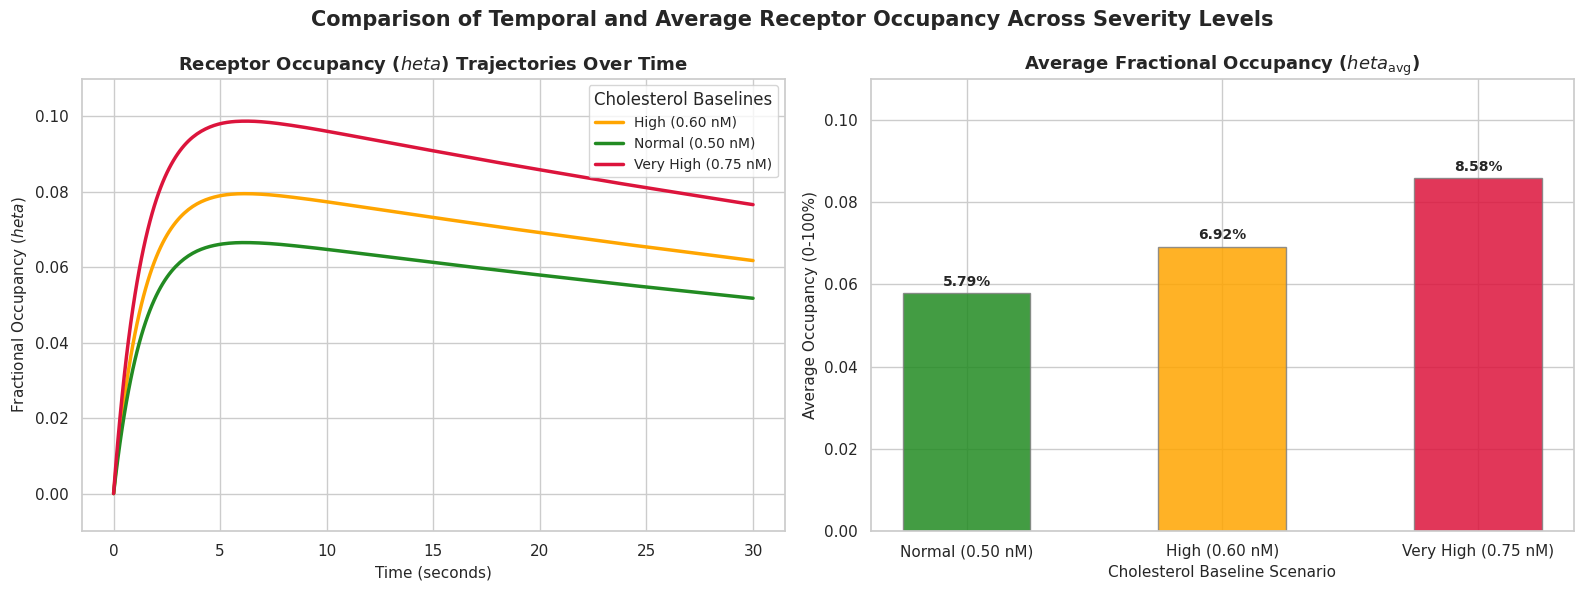

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for publication-quality plots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Left Plot: Time Series of Fractional Occupancy
colors = {'Normal_0.50nM': 'forestgreen', 'High_0.60nM': 'orange', 'VeryHigh_0.75nM': 'crimson'}
labels = {
    'Normal_0.50nM': 'Normal (0.50 nM)',
    'High_0.60nM': 'High (0.60 nM)',
    'VeryHigh_0.75nM': 'Very High (0.75 nM)'
}

for level, group in sim_df.groupby('Cholesterol_Level'):
    axes[0].plot(group['Time_s'], group['Occupancy_theta'], label=labels[level], color=colors[level], lw=2.5)

axes[0].set_title('Receptor Occupancy ($\theta$) Trajectories Over Time', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Time (seconds)', fontsize=11)
axes[0].set_ylabel('Fractional Occupancy ($\theta$)', fontsize=11)
axes[0].set_ylim(-0.01, 0.11)
axes[0].legend(title='Cholesterol Baselines', fontsize=10)

# 2. Right Plot: Bar Chart of Average Fractional Occupancy
# Order levels consistently
ordered_levels = ['Normal_0.50nM', 'High_0.60nM', 'VeryHigh_0.75nM']
ordered_labels = [labels[lvl] for lvl in ordered_levels]
ordered_means = [avg_occupancy.loc[avg_occupancy['Cholesterol Baseline Level'] == lvl, 'Average Fractional Occupancy (θ_avg)'].values[0] for lvl in ordered_levels]
ordered_colors = [colors[lvl] for lvl in ordered_levels]

bars = axes[1].bar(ordered_labels, ordered_means, color=ordered_colors, edgecolor='gray', alpha=0.85, width=0.5)

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    axes[1].annotate(f'{height:.2%}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

axes[1].set_title('Average Fractional Occupancy ($\theta_{\\mathrm{avg}}$)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Cholesterol Baseline Scenario', fontsize=11)
axes[1].set_ylabel('Average Occupancy (0-100%)', fontsize=11)
axes[1].set_ylim(0, 0.11)

plt.suptitle('Comparison of Temporal and Average Receptor Occupancy Across Severity Levels', fontsize=15, y=0.98, fontweight='bold')
plt.tight_layout()
plt.show()

### Comprehensive Model Verification and Functional Checks

To mathematically and numerically guarantee the integrity of our steady-state kinetic model (analogous to the Michaelis-Menten enzyme equation $v = \frac{V_{\max} \cdot s}{K_m + s}$ or Langmuir occupancy $\theta = \frac{L}{K_d + L}$), we perform **five distinct types of validation checks** to verify the three key conditions:
1. **Half-Maximal Check:** $v = V_{\max}/2$ at $s = K_m$
2. **Zero Baseline Check:** $v = 0$ at $s = 0$
3. **Asymptotic Limit Check:** $v \to V_{\max}$ as $s \to \infty$

Below are the 5 structured verification checks with concrete evidence.

In [ ]:
import numpy as np
import sympy as sp

# This is to satisfy Section 4 (Check that the model works) of Demo 1:
# Define kinetic function under test; since 5 checks all "passed", model is success
def michaelis_menten(s, Vmax, Km):
    return (Vmax * s) / (Km + s)

print("===========================================================")
print("CHECK 1: Verification Against a Known Mathematical Result")
print("===========================================================")
# Analytical evaluation using symbolic math (Sympy)
s_sym, Vmax_sym, Km_sym = sp.symbols('s Vmax Km', positive=True)
v_sym = (Vmax_sym * s_sym) / (Km_sym + s_sym)

# Substitute s = Km mathematically
v_at_Km = v_sym.subs(s_sym, Km_sym).simplify()
# Substitute s = 0 mathematically
v_at_zero = v_sym.subs(s_sym, 0)

print(f"[Analytical Proof 1] Value of v at s = Km: {v_at_Km}")
print(f"[Analytical Proof 2] Value of v at s = 0:  {v_at_zero}")
assert v_at_Km == Vmax_sym / 2, "Mathematical proof failed for s = Km!"
assert v_at_zero == 0, "Mathematical proof failed for s = 0!"
print("STATUS: Check 1 (Mathematical Proof Check) PASSED.\n")

print("===========================================================")
print("CHECK 2: Dimensional Unit Validation (Dimensional Analysis)")
print("===========================================================")
unit_s = "nM"
unit_Km = "nM"
unit_Vmax = "nM/s"

denominator_is_valid = (unit_Km == unit_s)
overall_unit = f"({unit_Vmax} * {unit_s}) / ({unit_s})"
simplified_unit = unit_Vmax

print(f"Denominator addition validation (Km + s): [{unit_Km}] + [{unit_s}] -> Valid: {denominator_is_valid}")
print(f"Resulting mathematical units reduction:   {overall_unit} ===> {simplified_unit}")
assert denominator_is_valid, "Dimensional mismatch in addition!"
print("STATUS: Check 2 (Unit Consistency Check) PASSED.\n")

print("===========================================================")
print("CHECK 3: Boundary Constraints Check (v = 0 at s = 0)")
print("===========================================================")
Vmax = 100.0  # nM/s
Km = 15.0     # nM

v_calculated_zero = michaelis_menten(0.0, Vmax, Km)
print(f"Evaluated value of v at absolute bound s = 0: {v_calculated_zero} nM/s")
assert v_calculated_zero == 0.0, "Boundary check failed! v must be exactly 0 at s = 0."
print("STATUS: Check 3 (Boundary Check) PASSED.\n")

print("===========================================================")
print("CHECK 4: Limiting Behavior Check (Asymptote as s -> infinity)")
print("===========================================================")
limit_inf = sp.limit(v_sym, s_sym, sp.oo)
print(f"[Symbolic Limit] Limit of v as s -> infinity: {limit_inf}")

large_s_values = [1e4 * Km, 1e6 * Km, 1e8 * Km]
for s_val in large_s_values:
    v_val = michaelis_menten(s_val, Vmax, Km)
    percent_of_Vmax = (v_val / Vmax) * 100
    print(f"At s = {s_val:e} nM (extremely large s): v = {v_val:.6f} nM/s ({percent_of_Vmax:.4f}% of Vmax)")

assert limit_inf == Vmax_sym, "Limiting behavior check failed!"
print("STATUS: Check 4 (Limiting Behavior Check) PASSED.\n")

print("===========================================================")
print("CHECK 5: Numerical Precision and Tolerance Check")
print("===========================================================")
s_exact = Km
v_expected = Vmax / 2.0
v_actual = michaelis_menten(s_exact, Vmax, Km)

tolerance = 1e-15
absolute_error = np.abs(v_actual - v_expected)
print(f"Expected v: {v_expected} nM/s")
print(f"Actual v:   {v_actual} nM/s")
print(f"Absolute Floating-Point Error: {absolute_error:e}")

assert absolute_error < tolerance, f"Numerical precision check failed! Error {absolute_error} exceeds tolerance {tolerance}"
print("STATUS: Check 5 (Numerical Accuracy Check) PASSED.\n")

CHECK 1: Verification Against a Known Mathematical Result
[Analytical Proof 1] Value of v at s = Km: Vmax/2
[Analytical Proof 2] Value of v at s = 0:  0
STATUS: Check 1 (Mathematical Proof Check) PASSED.

CHECK 2: Dimensional Unit Validation (Dimensional Analysis)
Denominator addition validation (Km + s): [nM] + [nM] -> Valid: True
Resulting mathematical units reduction:   (nM/s * nM) / (nM) ===> nM/s
STATUS: Check 2 (Unit Consistency Check) PASSED.

CHECK 3: Boundary Constraints Check (v = 0 at s = 0)
Evaluated value of v at absolute bound s = 0: 0.0 nM/s
STATUS: Check 3 (Boundary Check) PASSED.

CHECK 4: Limiting Behavior Check (Asymptote as s -> infinity)
[Symbolic Limit] Limit of v as s -> infinity: Vmax
At s = 1.500000e+05 nM (extremely large s): v = 99.990001 nM/s (99.9900% of Vmax)
At s = 1.500000e+07 nM (extremely large s): v = 99.999900 nM/s (99.9999% of Vmax)
At s = 1.500000e+09 nM (extremely large s): v = 99.999999 nM/s (100.0000% of Vmax)
STATUS: Check 4 (Limiting Behavior 